Input shape: torch.Size([4, 4, 3])
Target shape: torch.Size([2])
Target: tensor([0.2500, 0.7500])


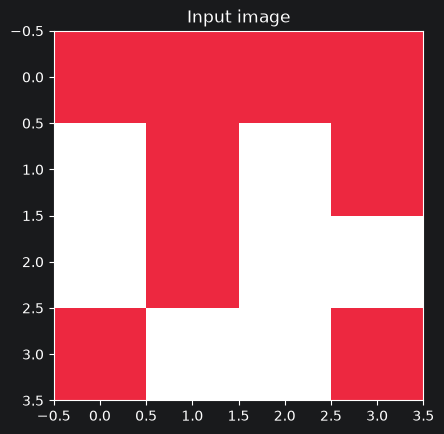

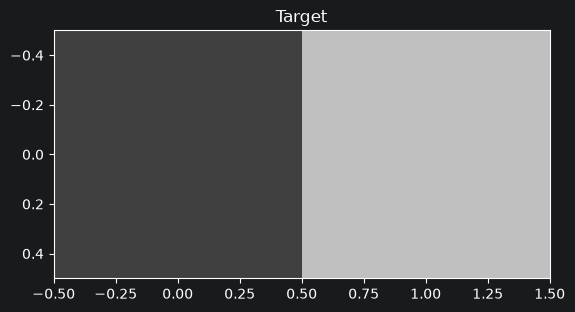

In [1]:
import torch
import matplotlib.pyplot as plt

from first_principles_models import LinearModel, LinearSigmoidModel
from data import get_logo_as_rgb_image_tensor
from utilities import (
    plot_grayscale_image_tensor,
    plot_rgb_image_tensor,
    plot_scalar_image_tensor
)

# RGB channel indices
RED, GREEN, BLUE = (0, 1, 2)

# Reproducibility
RANDOM_SEED = 0

# Input data
image = get_logo_as_rgb_image_tensor()

# Expected output
target = torch.tensor([0.25, 0.75], dtype=torch.float32)

# Verify dimensions
print("Input shape:", image.shape)
print("Target shape:", target.shape)
print("Target:", target)

# Visualize input and target
plot_rgb_image_tensor(image, "Input image")
plot_grayscale_image_tensor(target.unsqueeze(0), "Target")

In [2]:
# Part I - Exercise 1: LinearModel

torch.manual_seed(RANDOM_SEED)

linear_model = LinearModel(image.shape, target.shape)

# Verify initial model state
print("Weights shape:", linear_model.weights.shape)

# Initial prediction
initial_output = linear_model.calculate_output(image)
initial_loss = linear_model.calculate_loss(initial_output, target)

print("Initial output:", initial_output)
print("Initial loss:", initial_loss.item())



Weights shape: torch.Size([4, 4, 3, 2])
Initial output: tensor([-0.0861,  0.8424])
Initial loss: 0.060756031423807144


### EXC 1 : Linear update with two steps

Output: tensor([-0.0861,  0.8424]) | Shape: torch.Size([2])
Target: tensor([0.2500, 0.7500]) | Shape: torch.Size([2])
Predict error: tensor([-0.3361,  0.0924]) | Shape: torch.Size([2])

Step 1:
Output: tensor([-0.0861,  0.8424])
Loss: 0.06075603
Output: tensor([0.0135, 0.8150]) | Shape: torch.Size([2])
Target: tensor([0.2500, 0.7500]) | Shape: torch.Size([2])
Predict error: tensor([-0.2365,  0.0650]) | Shape: torch.Size([2])

Step 2:
Output: tensor([0.0135, 0.8150])
Loss: 0.03008771

Final output: tensor([0.0835, 0.7958])
Final loss: 0.01490008


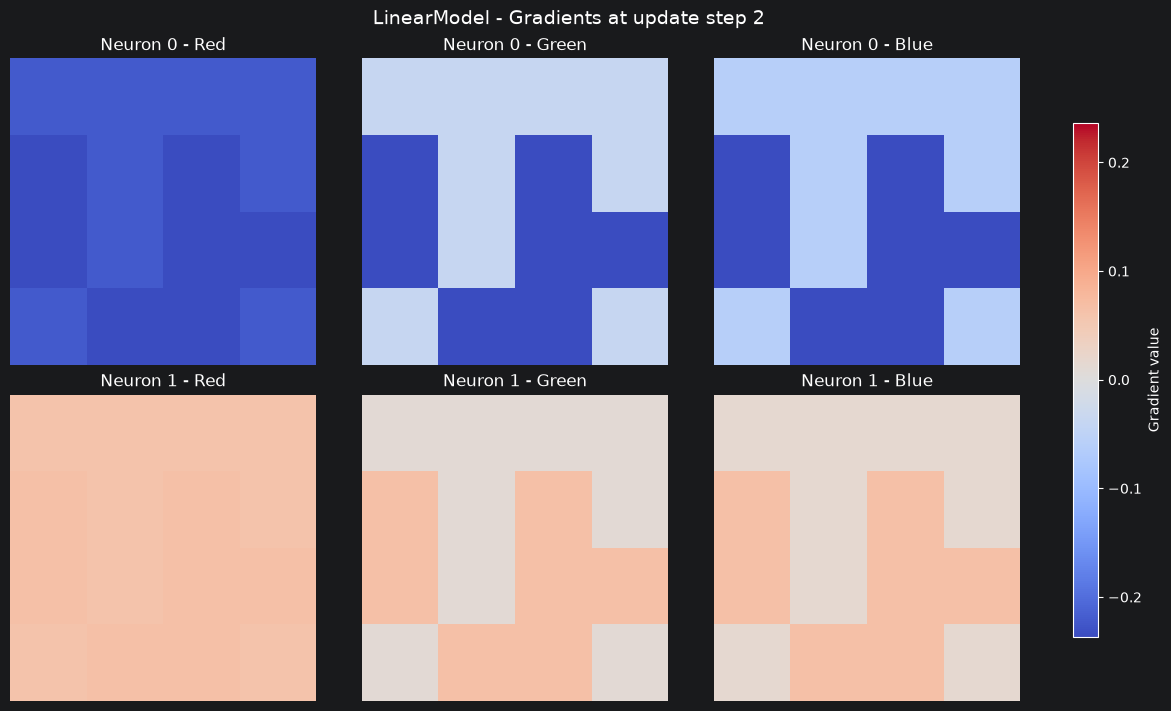

In [5]:
# ------------------------------------------------------------
# 1. Perform two training steps
# ------------------------------------------------------------
learning_rate = 0.01

for step in range(1, 3):

    output = linear_model.calculate_output(image)
    loss = linear_model.calculate_loss(output, target)
    gradients = linear_model.calculate_gradients(image, output, target)

    # Save gradients of the SECOND update step
    if step == 2:
        gradients_step2 = gradients.detach().clone()
        output_step2 = output.detach().clone()

    print(f"\nStep {step}:")
    print(f"Output: {output}")
    print(f"Loss: {loss.item():.8f}")

    # Update weights
    linear_model.update_weights(gradients, learning_rate)

# ------------------------------------------------------------
# 2. Final results after both updates
# ------------------------------------------------------------

final_output = linear_model.calculate_output(image)
final_loss = linear_model.calculate_loss(final_output, target)

print("\nFinal output:", final_output)
print(f"Final loss: {final_loss.item():.8f}")

# ------------------------------------------------------------
# 3. Visualize gradients from second update step
# ------------------------------------------------------------

channels = ["Red", "Green", "Blue"]

fig, axes = plt.subplots(
    2, 3,
    figsize=(12, 7),
    constrained_layout=True
)

# Shared color scale across all six plots
limit = max(gradients_step2.abs().max().item(), 1e-8)

for neuron in range(2):
    for channel in range(3):

        gradient_image = gradients_step2[:, :, channel, neuron]

        im = axes[neuron, channel].imshow(
            gradient_image.cpu().numpy(),
            cmap="coolwarm",
            vmin=-limit,
            vmax=limit,
            interpolation="nearest"
        )

        axes[neuron, channel].set_title(
            f"Neuron {neuron} - {channels[channel]}"
        )
        axes[neuron, channel].axis("off")

fig.colorbar(
    im,
    ax=axes,
    label="Gradient value",
    shrink=0.8
)

fig.suptitle(
    "LinearModel - Gradients at update step 2",
    fontsize=14
)

# Save figure for the report
plt.savefig(
    "part1_linear_gradients.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### EXC 2 : LinearSigmoidModel with 2 update steps

Weights shape: torch.Size([4, 4, 3, 2])
Initial output: tensor([0.4785, 0.6990])
Initial loss: 0.027404479682445526

Step 1:
Output: tensor([0.4785, 0.6990])
Loss: 0.02740448

Step 2:
Output: tensor([0.3956, 0.7122])
Loss: 0.01130998

Final output: tensor([0.3475, 0.7215])
Final loss: 0.00515556


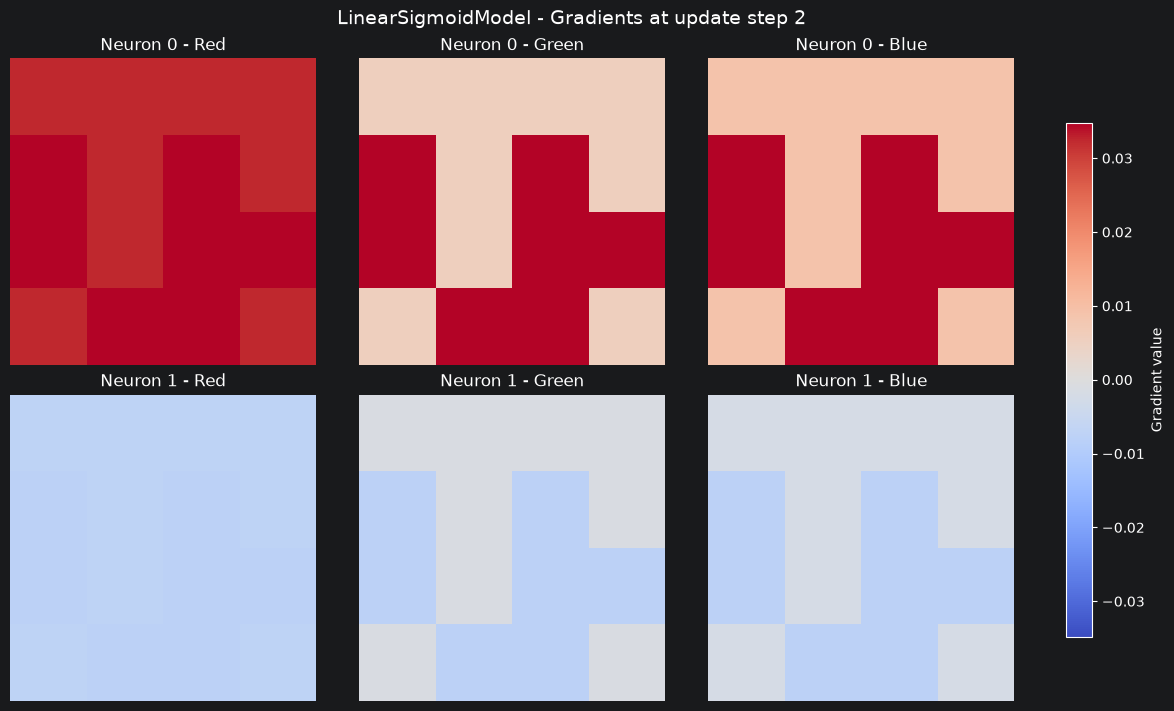

In [4]:
# ------------------------------------------------------------
# 1. Initialize LinearSigmoidModel
# ------------------------------------------------------------

torch.manual_seed(RANDOM_SEED)

sigmoid_model = LinearSigmoidModel(image.shape, target.shape)
sigmoid_learning_rate = 0.2

print("Weights shape:", sigmoid_model.weights.shape)

initial_output = sigmoid_model.calculate_output(image)
initial_loss = sigmoid_model.calculate_loss(initial_output, target)

print("Initial output:", initial_output)
print("Initial loss:", initial_loss.item())

# ------------------------------------------------------------
# 2. Perform two training steps
# ------------------------------------------------------------

for step in range(1, 3):

    output = sigmoid_model.calculate_output(image)
    loss = sigmoid_model.calculate_loss(output, target)
    gradients = sigmoid_model.calculate_gradients(image, output, target)

    # Save gradients BEFORE the second weight update
    if step == 2:
        sigmoid_gradients_step2 = gradients.detach().clone()
        sigmoid_output_step2 = output.detach().clone()
        sigmoid_loss_step2 = loss.item()

    print(f"\nStep {step}:")
    print(f"Output: {output}")
    print(f"Loss: {loss.item():.8f}")

    sigmoid_model.update_weights(gradients, sigmoid_learning_rate)

# ------------------------------------------------------------
# 3. Final results after both updates
# ------------------------------------------------------------

final_output = sigmoid_model.calculate_output(image)
final_loss = sigmoid_model.calculate_loss(final_output, target)

print("\nFinal output:", final_output)
print(f"Final loss: {final_loss.item():.8f}")

# ------------------------------------------------------------
# 4. Visualize gradients from second update step
# ------------------------------------------------------------

channels = ["Red", "Green", "Blue"]

fig, axes = plt.subplots(
    2, 3,
    figsize=(12, 7),
    constrained_layout=True
)

# Shared color scale across all six plots
limit = max(sigmoid_gradients_step2.abs().max().item(), 1e-8)

for neuron in range(2):
    for channel in range(3):

        gradient_image = sigmoid_gradients_step2[:, :, channel, neuron]

        im = axes[neuron, channel].imshow(
            gradient_image.cpu().numpy(),
            cmap="coolwarm",
            vmin=-limit,
            vmax=limit,
            interpolation="nearest"
        )

        axes[neuron, channel].set_title(
            f"Neuron {neuron} - {channels[channel]}"
        )
        axes[neuron, channel].axis("off")

fig.colorbar(
    im,
    ax=axes,
    label="Gradient value",
    shrink=0.8
)

fig.suptitle(
    "LinearSigmoidModel - Gradients at update step 2",
    fontsize=14
)

# Save figure for the report
plt.savefig(
    "part1_sigmoid_gradients.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### EXC 3 :  LinearSigmoidModel on the sample for 10 update steps


Learning rate: 0.0001
[LinearSigmoidModel] fit step 1/10: loss = 0.027404479682445526
[LinearSigmoidModel] fit step 2/10: loss = 0.02739451266825199
[LinearSigmoidModel] fit step 3/10: loss = 0.027384549379348755
[LinearSigmoidModel] fit step 4/10: loss = 0.02737458609044552
[LinearSigmoidModel] fit step 5/10: loss = 0.02736463025212288
[LinearSigmoidModel] fit step 6/10: loss = 0.027354665100574493
[LinearSigmoidModel] fit step 7/10: loss = 0.0273447148501873
[LinearSigmoidModel] fit step 8/10: loss = 0.027334770187735558
[LinearSigmoidModel] fit step 9/10: loss = 0.02732481248676777
[LinearSigmoidModel] fit step 10/10: loss = 0.02731487713754177

Learning rate: 0.001
[LinearSigmoidModel] fit step 1/10: loss = 0.027404479682445526
[LinearSigmoidModel] fit step 2/10: loss = 0.027304857969284058
[LinearSigmoidModel] fit step 3/10: loss = 0.027205590158700943
[LinearSigmoidModel] fit step 4/10: loss = 0.027106715366244316
[LinearSigmoidModel] fit step 5/10: loss = 0.02700822241604328
[L

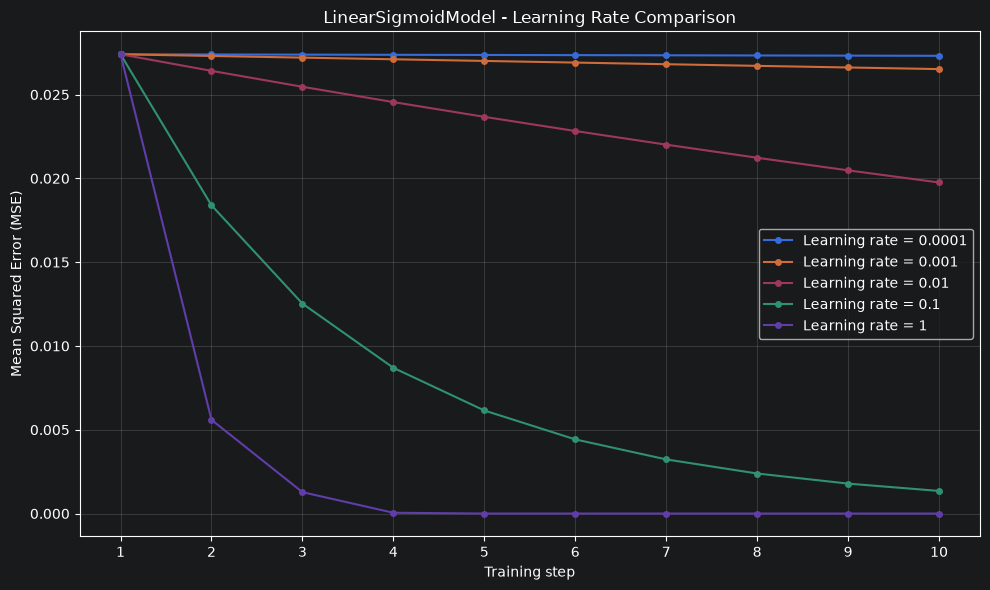


Final loss after 10 update steps:
----------------------------------------
Learning rate 0.0001 : MSE = 0.0273049362
Learning rate 0.001  : MSE = 0.0264250394
Learning rate 0.01   : MSE = 0.0190592818
Learning rate 0.1    : MSE = 0.0010246782
Learning rate 1      : MSE = 0.0000000000

Lowest final loss: learning rate = 1


In [3]:
# ------------------------------------------------------------
# 1. Experiment settings
# ------------------------------------------------------------

learning_rates = [0.0001, 0.001, 0.01, 0.1, 1]
training_steps = 10

loss_curves = {}
final_losses = {}

# ------------------------------------------------------------
# 2. Train a new model for each learning rate
# ------------------------------------------------------------

for lr in learning_rates:

    # Same initial weights for a fair comparison
    torch.manual_seed(RANDOM_SEED)

    model = LinearSigmoidModel(image.shape, target.shape)

    print(f"\n{'='*45}")
    print(f"Learning rate: {lr}")
    print(f"{'='*45}")

    # Train for 10 update steps
    loss_history = model.fit(
        image,
        target,
        steps=training_steps,
        learning_rate=lr
    )

    # Store loss history
    loss_curves[lr] = loss_history

    # Calculate loss after the final weight update
    final_output = model.calculate_output(image)
    final_loss = model.calculate_loss(final_output, target)

    final_losses[lr] = final_loss.item()

# ------------------------------------------------------------
# 3. Visualize all training loss curves
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

for lr, losses in loss_curves.items():

    plt.plot(
        range(1, training_steps + 1),
        losses,
        marker="o",
        markersize=4,
        label=f"Learning rate = {lr}"
    )

plt.xlabel("Training step")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("LinearSigmoidModel - Learning Rate Comparison")

plt.xticks(range(1, training_steps + 1))
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

# Save figure for report
plt.savefig(
    "part1_learning_rates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 4. Compare final losses
# ------------------------------------------------------------

print("\nFinal loss after 10 update steps:")
print("-" * 40)

for lr, loss in final_losses.items():
    print(f"Learning rate {lr:<7}: MSE = {loss:.10f}")

best_lr = min(final_losses, key=final_losses.get)

print(f"\nLowest final loss: learning rate = {best_lr}")